<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Keep repeated identifiers and their namespaces

**What disappears when a repeating field is reduced to its first value?**
We will parse synthetic HL7 v2 text, inspect its declared separators, expand every
PID-3 repetition, and compare the full identifier inventory with a first-value view.
We will also keep empty, absent, malformed and SQL NULL inputs distinguishable.

All seven payload rows and identifiers are invented. This is a parser demonstration,
not patient matching, clinical interpretation, or a conformance assessment. No real
patient data or external service is involved. A namespace-qualified identifier key
in this sample is not evidence that two records represent the same person.

## Choose whether the view includes later repetitions

The default `INCLUDE_REPEATS=True` keeps all nonempty identifier repetitions.
The experiment sets it to `False`, retaining repetition zero only. The full expanded
table and original payloads remain available for comparison under either choice.
[Run instructions](README.md).

In [1]:
INCLUDE_REPEATS = True

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from notebook_support import finish, prose, theme

if type(INCLUDE_REPEATS) is not bool:
    raise ValueError("INCLUDE_REPEATS must be True or False.")
comparison = authorities = key_counts = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-hl7/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-hl7/notebooks/pyproject.toml.

## Connect to the pinned release

This literal launcher downloads the public v0.4.0 JAR, checks its SHA-256 and starts
Java 21+. Cached bytes are verified on every launch. No Gradle or local worker build
is needed. The worker's pure-Java parser accepts inline text or UTF-8 bytes; a string
argument is the message itself, not a path to a file.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'hl7' (TYPE vgi,
 LOCATION 'uv run --frozen --project . python release_jar.py Query-farm/vgi-hl7 v0.4.0 vgi-hl7-v0.4.0.jar ec9a95f3f5f81a905402151d0eba493012e00ea4d7f54e3f03b0969c97c45633');

,Success


## Define a small, inspectable message inventory

A and B contain repeated identifiers. C declares custom separators (`#` and `*`
instead of `|` and `^`). D contains only a short MSH header, E has a present but empty
PID-3 field, F has no MSH header, and G is SQL NULL. Named macros keep each table-function
argument a literal while allowing the same payload to appear in several SQL examples.

`is_valid_hl7` reports whether this parser accepts the text. D demonstrates that the
flag alone does not establish required fields, a complete message profile, or usable
identifiers. Preserve that distinction when reading the inventory.

In [4]:
%%sql
CREATE MACRO message_a() AS E'MSH|^~\\&|DEMO|LAB|RECV|DEST|20260101090000||ADT^A01|A|T|2.5\rPID|1||1001^^^HOSP^MR~X55^^^LAB^AN~1001^^^RESEARCH^PI';
CREATE MACRO message_b() AS E'MSH|^~\\&|DEMO|LAB|RECV|DEST|20260101090100||ADT^A01|B|T|2.5\rPID|1||1002^^^HOSP^MR~X56^^^LAB^AN';
CREATE MACRO message_c() AS E'MSH#*!/@#DEMO#LAB#RECV#DEST#20260101090200##ADT*A01#C#T#2.5\rPID#1##1001***OTHERHOSP*MR';
CREATE MACRO message_d() AS E'MSH|^~\\&';
CREATE MACRO message_e() AS E'MSH|^~\\&|DEMO|LAB|RECV|DEST|20260101090400||ADT^A01|E|T|2.5\rPID|1||||';
CREATE MACRO message_f() AS E'PID|1||BROKEN';
CREATE MACRO message_g() AS NULL;
CREATE TABLE messages AS
SELECT 'A' AS message_key,message_a() AS payload
UNION ALL SELECT 'B' AS message_key,message_b() AS payload
UNION ALL SELECT 'C' AS message_key,message_c() AS payload
UNION ALL SELECT 'D' AS message_key,message_d() AS payload
UNION ALL SELECT 'E' AS message_key,message_e() AS payload
UNION ALL SELECT 'F' AS message_key,message_f() AS payload
UNION ALL SELECT 'G' AS message_key,message_g() AS payload;

CREATE TABLE inventory AS
 SELECT *,hl7.main.is_valid_hl7(payload) AS parses,
        hl7.main.hl7_message_control_id(payload) AS control_id,
        hl7.main.hl7_message_type(payload) AS message_type,
        hl7.main.hl7_version(payload) AS version
 FROM messages;
SELECT message_key,parses,control_id,message_type,version FROM inventory ORDER BY message_key;

,message_key,parses,control_id,message_type,version
0,A,True,A,ADT^A01,2.5
1,B,True,B,ADT^A01,2.5
2,C,True,C,ADT*A01,2.5
3,D,True,None,None,None
4,E,True,E,ADT^A01,2.5
5,F,False,None,None,None
6,G,<NA>,None,None,None


## Read separators and compare segment and field views

MSH-1 is the field separator itself and MSH-2 contains the encoding characters.
Read the complete MSH-2 value from `hl7_fields`: in this pinned release, `hl7_get`
applies first-repetition semantics even to MSH-2 and returns only its prefix. The
comparison below makes that limitation visible; it is not used as the full encoding.

Each `hl7_get` location is materialized in a separate statement to avoid the current
engine's documented constant-argument expression-merging issue. The PID-3 scalar
returns only repetition zero. `hl7_segments` preserves segment order, while
`hl7_fields` expands field repetitions. Segment and field repetition indices are
zero-based, and field numbers are one-based. The field table preserves MSH-2 verbatim.

In [5]:
%%sql
CREATE TABLE scalar_encoding AS
 SELECT message_key,hl7.main.hl7_get(payload,'MSH-2') AS scalar_encoding_prefix FROM messages;
CREATE TABLE first_identifiers AS
 SELECT message_key,hl7.main.hl7_get(payload,'PID-3') AS first_identifier FROM messages;
SELECT * FROM hl7.main.hl7_segments(message_c()) ORDER BY seq;

,seq,segment,field_count,raw
0,1,MSH,12,MSH#*!/@#DEMO#LAB#RECV#DEST#20260101090200##AD...
1,2,PID,3,PID#1##1001***OTHERHOSP*MR


In [6]:
%%sql
CREATE TABLE field_rows AS
SELECT 'A' AS message_key,f.* FROM hl7.main.hl7_fields(message_a()) f
UNION ALL SELECT 'B' AS message_key,f.* FROM hl7.main.hl7_fields(message_b()) f
UNION ALL SELECT 'C' AS message_key,f.* FROM hl7.main.hl7_fields(message_c()) f
UNION ALL SELECT 'D' AS message_key,f.* FROM hl7.main.hl7_fields(message_d()) f
UNION ALL SELECT 'E' AS message_key,f.* FROM hl7.main.hl7_fields(message_e()) f
UNION ALL SELECT 'F' AS message_key,f.* FROM hl7.main.hl7_fields(message_f()) f
UNION ALL SELECT 'G' AS message_key,f.* FROM hl7.main.hl7_fields(message_g()) f;

CREATE TABLE encoding AS
 SELECT i.message_key,f.value AS encoding_chars FROM inventory i LEFT JOIN field_rows f
 ON i.message_key=f.message_key AND f.segment='MSH' AND f.field=2 AND f.segment_rep=0 AND f.repetition=0;
SELECT message_key,segment,segment_rep,field,repetition,value
FROM field_rows WHERE (segment='PID' AND field=3) OR (segment='MSH' AND field<=2)
ORDER BY message_key,segment,segment_rep,field,repetition;

,message_key,segment,segment_rep,field,repetition,value
0,A,MSH,0,1,0,|
1,A,MSH,0,2,0,^~\&
2,A,PID,0,3,0,1001^^^HOSP^MR
3,A,PID,0,3,1,X55^^^LAB^AN
4,A,PID,0,3,2,1001^^^RESEARCH^PI
5,B,MSH,0,1,0,|
6,B,MSH,0,2,0,^~\&
7,B,PID,0,3,0,1002^^^HOSP^MR
8,B,PID,0,3,1,X56^^^LAB^AN
9,C,MSH,0,1,0,#


In [7]:
%%sql
SELECT e.message_key,e.encoding_chars,s.scalar_encoding_prefix,f.first_identifier
FROM encoding e JOIN scalar_encoding s USING(message_key)
JOIN first_identifiers f USING(message_key) ORDER BY e.message_key;


,message_key,encoding_chars,scalar_encoding_prefix,first_identifier
0,A,^~\&,^,1001^^^HOSP^MR
1,B,^~\&,^,1002^^^HOSP^MR
2,C,*!/@,*,1001***OTHERHOSP*MR
3,D,^~\&,^,None
4,E,^~\&,^,
5,F,None,None,None
6,G,None,None,None


## Expand identifier components using the declared separator

Each PID-3 repetition is retained with its message, segment and repetition indices.
For this deliberately simple sample, component 1 is the identifier text, component 4
the assigning-authority namespace, and component 5 the identifier type. We split on
the declared component character, so C is parsed without assuming `^` everywhere.

This example has no escapes or nested authority subcomponents. It does not implement
general CX validation, escape decoding, namespace governance, or entity resolution.
The raw field value remains available alongside the extracted components.

In [8]:
%%sql
CREATE TABLE identifier_fields AS
 SELECT f.*,substr(e.encoding_chars,1,1) AS component_separator
 FROM field_rows f JOIN encoding e USING(message_key) WHERE f.segment='PID' AND f.field=3;
CREATE TABLE identifiers AS
 SELECT *,nullif(split_part(value,component_separator,1),'') AS identifier_text,
          nullif(split_part(value,component_separator,4),'') AS authority,
          nullif(split_part(value,component_separator,5),'') AS identifier_type
 FROM identifier_fields;
CREATE TABLE selected_identifiers AS
 SELECT * FROM identifiers WHERE identifier_text IS NOT NULL
 AND ({{ INCLUDE_REPEATS }} OR repetition=0);
SELECT message_key,segment_rep,repetition,value,identifier_text,authority,identifier_type
FROM identifiers ORDER BY message_key,segment_rep,repetition;

,message_key,segment_rep,repetition,value,identifier_text,authority,identifier_type
0,A,0,0,1001^^^HOSP^MR,1001,HOSP,MR
1,A,0,1,X55^^^LAB^AN,X55,LAB,AN
2,A,0,2,1001^^^RESEARCH^PI,1001,RESEARCH,PI
3,B,0,0,1002^^^HOSP^MR,1002,HOSP,MR
4,B,0,1,X56^^^LAB^AN,X56,LAB,AN
5,C,0,0,1001***OTHERHOSP*MR,1001,OTHERHOSP,MR
6,E,0,0,,None,None,None


## Retain absence and input failures in the inventory

A missing PID-3 field has no value to count, while E's present empty field is observable
and contains zero nonempty identifiers. Invalid and SQL NULL messages also remain
visible. The comparison chart includes only messages with an observed PID-3 field;
the other inventory rows retain NULL counts instead of fabricated zeros.

In [9]:
%%sql
CREATE TABLE counts_by_message AS
WITH full_counts AS (
 SELECT message_key,count(*) AS field_repetitions,
        count(identifier_text) AS full_identifiers FROM identifiers GROUP BY message_key
), selected_counts AS (
 SELECT message_key,count(*) AS selected_identifiers FROM selected_identifiers GROUP BY message_key
)
SELECT i.message_key,i.parses,i.control_id,
 CASE WHEN i.payload IS NULL THEN 'SQL NULL payload'
      WHEN NOT i.parses THEN 'Parser rejected'
      WHEN f.message_key IS NULL THEN 'PID-3 absent'
      WHEN f.full_identifiers=0 THEN 'PID-3 present, empty'
      ELSE 'Nonempty identifiers observed' END AS input_state,
 f.field_repetitions,f.full_identifiers,
 CASE WHEN f.message_key IS NOT NULL THEN coalesce(s.selected_identifiers,0) END AS selected_identifiers
FROM inventory i LEFT JOIN full_counts f USING(message_key)
LEFT JOIN selected_counts s USING(message_key);
SELECT * FROM counts_by_message ORDER BY message_key;

,message_key,parses,control_id,input_state,field_repetitions,full_identifiers,selected_identifiers
0,A,True,A,Nonempty identifiers observed,3,3,3
1,B,True,B,Nonempty identifiers observed,2,2,2
2,C,True,C,Nonempty identifiers observed,1,1,1
3,D,True,None,PID-3 absent,<NA>,<NA>,<NA>
4,E,True,E,"PID-3 present, empty",1,0,0
5,F,False,None,Parser rejected,<NA>,<NA>,<NA>
6,G,<NA>,None,SQL NULL payload,<NA>,<NA>,<NA>


In [10]:
%%sql comparison <<
SELECT * FROM counts_by_message WHERE field_repetitions IS NOT NULL ORDER BY message_key;

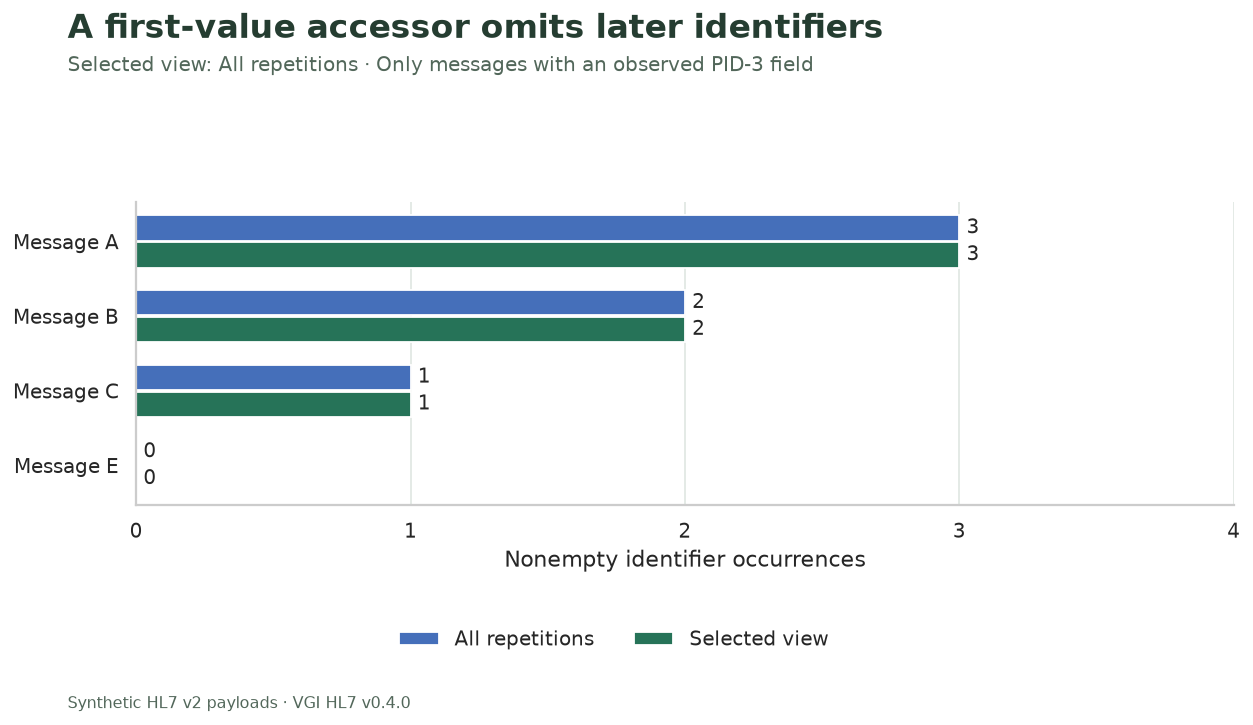

The selected view retains **6 of 6 nonempty identifier occurrences**. It omits **0** later occurrences. Message E remains a known zero; D, F and G remain outside this chart with their distinct diagnostic states.

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.6))
y = np.arange(len(comparison))
for offset, column, color, label in [
    (-0.18, "full_identifiers", "#456fba", "All repetitions"),
    (0.18, "selected_identifiers", "#267358", "Selected view"),
]:
    bars = ax.barh(y + offset, comparison[column], height=0.34, color=color, label=label)
    ax.bar_label(bars, padding=4, fontsize=11)
ax.set_yticks(y, [f"Message {k}" for k in comparison.message_key])
ax.invert_yaxis()
ax.set_xlim(0, 4)
ax.set_xlabel("Nonempty identifier occurrences")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.08),
    ncol=2,
    frameon=False,
)
mode = "All repetitions" if INCLUDE_REPEATS else "First repetition only"
finish(
    fig,
    "A first-value accessor omits later identifiers",
    f"Selected view: {mode} · Only messages with an observed PID-3 field",
    "01_identifier_retention.png",
    bottom=0.18,
)
full_count = int(comparison.full_identifiers.sum())
selected_count = int(comparison.selected_identifiers.sum())
prose(
    f"The selected view retains **{selected_count} of {full_count} nonempty identifier occurrences**. "
    f"It omits **{full_count - selected_count}** later occurrences. Message E remains a known zero; "
    "D, F and G remain outside this chart with their distinct diagnostic states."
)

## Count namespace-qualified keys separately from bare strings

The text `1001` appears in multiple assigning authorities. Counting distinct identifier
strings alone merges those namespaces. Here we define a **sample key** as
`(authority, identifier_type, identifier_text)` and report both measures. Neither is a
count of people, and repeated fields are not additional messages.

In [12]:
%%sql authorities <<
WITH full_counts AS (
 SELECT authority,count(*) AS all_occurrences FROM identifiers
 WHERE identifier_text IS NOT NULL GROUP BY authority
), selected_counts AS (
 SELECT authority,count(*) AS selected_occurrences FROM selected_identifiers GROUP BY authority
)
SELECT f.authority,f.all_occurrences,coalesce(s.selected_occurrences,0) AS selected_occurrences
FROM full_counts f LEFT JOIN selected_counts s USING(authority) ORDER BY f.authority;

In [13]:
%%sql key_counts <<
SELECT count(*) AS occurrences,count(DISTINCT identifier_text) AS bare_strings,
 count(DISTINCT (authority,identifier_type,identifier_text)) AS sample_keys
FROM selected_identifiers;

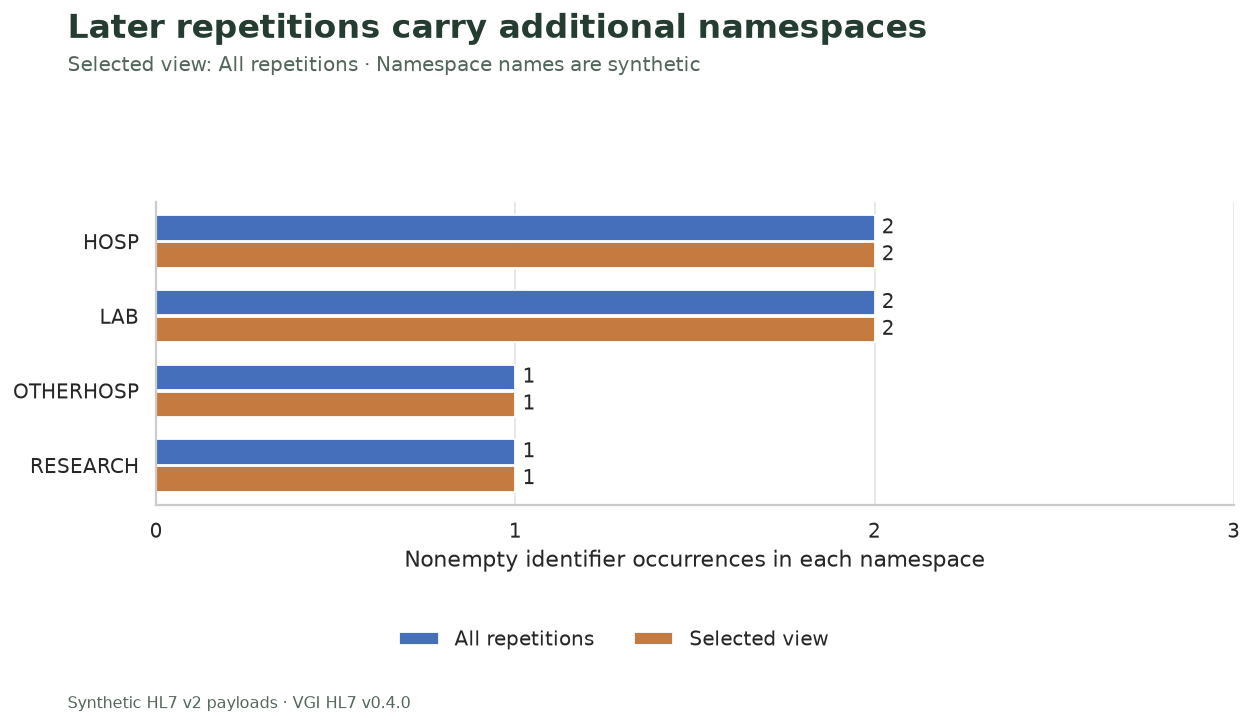

The selected view has **6 occurrences**, **4 distinct bare identifier strings**, and **6 distinct sample keys** including namespace and type. These counts describe the retained identifiers, not patients or unique entities.

In [14]:
fig, ax = plt.subplots(figsize=(10, 5.6))
y = np.arange(len(authorities))
for offset, column, color, label in [
    (-0.18, "all_occurrences", "#456fba", "All repetitions"),
    (0.18, "selected_occurrences", "#c57b40", "Selected view"),
]:
    bars = ax.barh(y + offset, authorities[column], height=0.34, color=color, label=label)
    ax.bar_label(bars, padding=4, fontsize=11)
ax.set_yticks(y, authorities.authority)
ax.invert_yaxis()
ax.set_xlim(0, 3)
ax.set_xlabel("Nonempty identifier occurrences in each namespace")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.08),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Later repetitions carry additional namespaces",
    f"Selected view: {mode} · Namespace names are synthetic",
    "02_namespace_coverage.png",
    bottom=0.18,
)
r = key_counts.iloc[0]
prose(
    f"The selected view has **{int(r.occurrences)} occurrences**, "
    f"**{int(r.bare_strings)} distinct bare identifier strings**, and "
    f"**{int(r.sample_keys)} distinct sample keys** including namespace and type. "
    "These counts describe the retained identifiers, not patients or unique entities."
)

## Verify row grain, separators and the declared selection

The checks compare the first-value scalar with repetition zero from the expanded
table, verify custom-separator handling, and preserve missing/empty distinctions.
Passing them establishes how this sample was parsed and counted; it does not establish
clinical validity or an identity match.

In [15]:
%%sql checks <<
SELECT 'All seven input row keys survive inventory classification' AS invariant,
 (SELECT count(*)=7 AND count(DISTINCT message_key)=7 FROM counts_by_message) AS passed
UNION ALL SELECT 'Malformed and SQL NULL inputs produce no field rows',
 NOT EXISTS(SELECT 1 FROM field_rows WHERE message_key IN ('F','G'))
UNION ALL SELECT 'The short header parses without inventing control ID or PID-3',
 (SELECT parses AND control_id IS NULL AND field_repetitions IS NULL FROM counts_by_message WHERE message_key='D')
UNION ALL SELECT 'The present empty field remains visible as a known zero',
 (SELECT count(*)=1 AND min(value)='' FROM identifiers WHERE message_key='E')
 AND (SELECT full_identifiers=0 AND selected_identifiers=0 FROM counts_by_message WHERE message_key='E')
UNION ALL SELECT 'MSH-2 is one verbatim field per parsed message',
 (SELECT count(*)=5 FROM field_rows WHERE segment='MSH' AND field=2)
 AND NOT EXISTS(SELECT 1 FROM field_rows f JOIN encoding e USING(message_key)
   WHERE f.segment='MSH' AND f.field=2 AND (f.repetition!=0 OR f.value IS DISTINCT FROM split_part((SELECT payload FROM messages m WHERE m.message_key=f.message_key),substr((SELECT payload FROM messages m WHERE m.message_key=f.message_key),4,1),2)))
UNION ALL SELECT 'Scalar first values equal repetition zero of the expanded field',
 NOT EXISTS(SELECT 1 FROM identifiers i JOIN first_identifiers f USING(message_key)
   WHERE i.segment_rep=0 AND i.repetition=0 AND i.value IS DISTINCT FROM f.first_identifier)
UNION ALL SELECT 'Custom separators yield the intended synthetic components',
 (SELECT identifier_text='1001' AND authority='OTHERHOSP' AND identifier_type='MR'
   FROM identifiers WHERE message_key='C')
UNION ALL SELECT 'Expanded field identities are unique',
 (SELECT count(*)=count(DISTINCT (message_key,segment,segment_rep,field,repetition)) FROM field_rows)
UNION ALL SELECT 'Selected identifiers retain their original expanded rows',
 NOT EXISTS((SELECT * FROM selected_identifiers) EXCEPT ALL (SELECT * FROM identifiers))
UNION ALL SELECT 'The view applies exactly the declared repetition policy',
 (SELECT count(*) FROM selected_identifiers)=
 (SELECT count(*) FROM identifiers WHERE identifier_text IS NOT NULL AND ({{ INCLUDE_REPEATS }} OR repetition=0))
UNION ALL SELECT 'All nonempty sample identifiers have namespace and type',
 NOT EXISTS(SELECT 1 FROM identifiers WHERE identifier_text IS NOT NULL AND (authority IS NULL OR identifier_type IS NULL))
UNION ALL SELECT 'Selected per-message counts reconcile with identifier rows',
 (SELECT sum(selected_identifiers) FROM counts_by_message)=(SELECT count(*) FROM selected_identifiers);

In [16]:
display(checks)
assert checks.passed.eq(True).all(), checks.loc[~checks.passed].to_dict("records")
prose(
    f"**{len(checks)} checks passed.** The original inputs and all expanded fields remain available "
    "even when the selected view deliberately omits later repetitions."
)

,invariant,passed
0,All seven input row keys survive inventory cla...,True
1,Malformed and SQL NULL inputs produce no field...,True
2,The short header parses without inventing cont...,True
3,The present empty field remains visible as a k...,True
4,MSH-2 is one verbatim field per parsed message,True
5,Scalar first values equal repetition zero of t...,True
6,Custom separators yield the intended synthetic...,True
7,Expanded field identities are unique,True
8,Selected identifiers retain their original exp...,True
9,The view applies exactly the declared repetiti...,True


**12 checks passed.** The original inputs and all expanded fields remain available even when the selected view deliberately omits later repetitions.

## Experiment: retain only the first repetition

Change only `INCLUDE_REPEATS` to `False`, restart and run all. Predict which namespaces
disappear and how the distinction between bare strings and sample keys changes.
Compare the selected view with the raw expanded field table; do not relabel the
omitted values as missing source data. Restore `True` for the saved default.

For larger feeds, preserve message identity and field repetition indices before
joining or aggregating. This notebook's macros are small literal examples, not a
general batch table-function interface or a complete HL7 implementation guide.

In [17]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)